
Dataset Loaded Successfully!

First 5 Rows:
   Fan  Refrigerator  AirConditioner  Television  Monitor  MotorPump  Month  \
0   16          23.0             2.0         6.0      1.0          0     10   
1   19          22.0             2.0         3.0      1.0          0      5   
2    7          20.0             2.0         6.0      7.0          0      7   
3    7          22.0             3.0        21.0      1.0          0      6   
4   11          23.0             2.0        11.0      1.0          0      2   

        City                                    Company  MonthlyHours  \
0  Hyderabad                    Tata Power Company Ltd.           384   
1   Vadodara                                       NHPC           488   
2     Shimla                            Jyoti Structure           416   
3     Mumbai                            Power Grid Corp           475   
4     Mumbai  Ratnagiri Gas and Power Pvt. Ltd. (RGPPL)           457   

   TariffRate  ElectricityBill  
0       

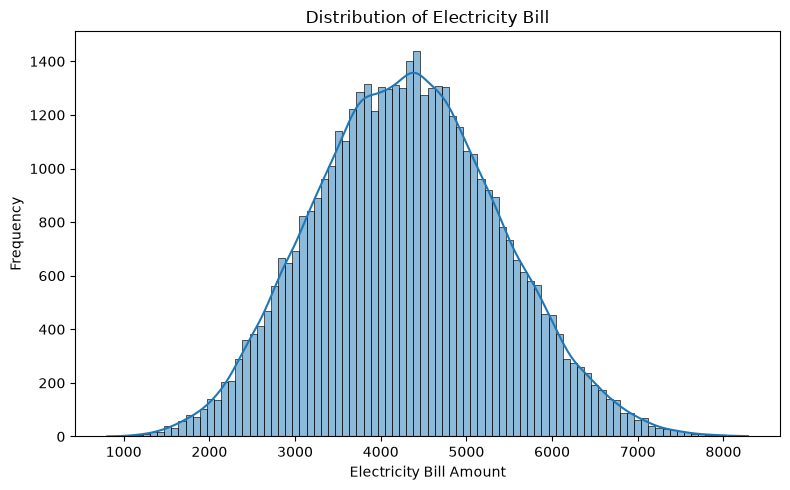

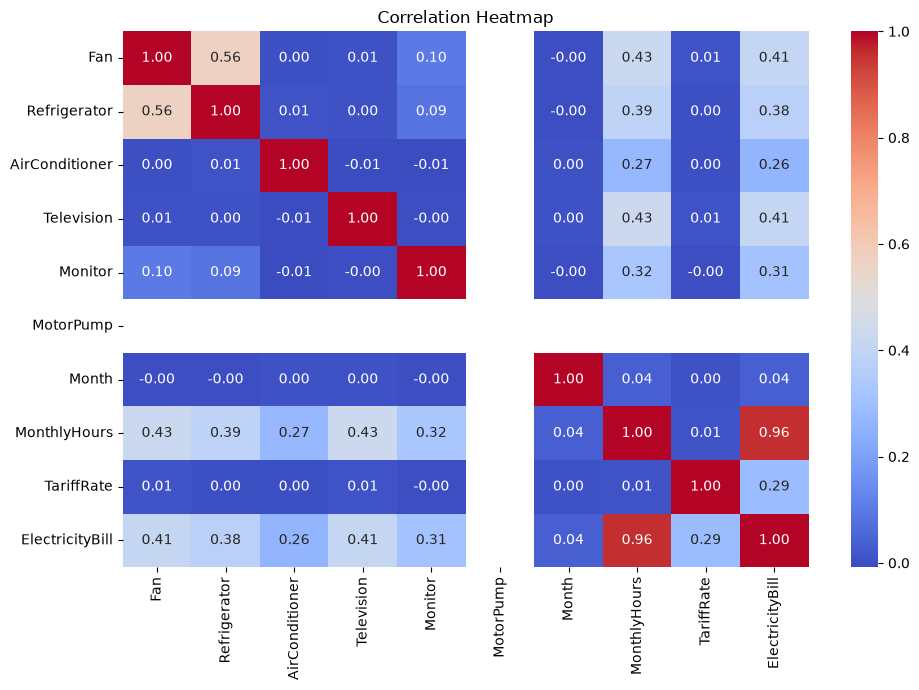

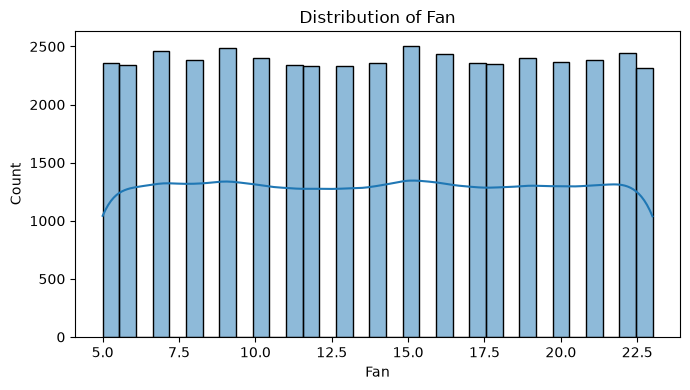

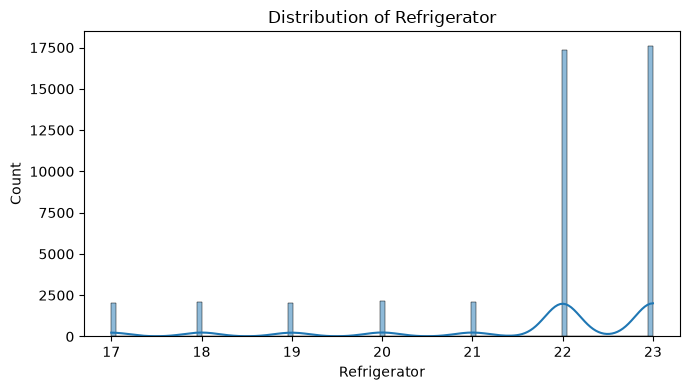

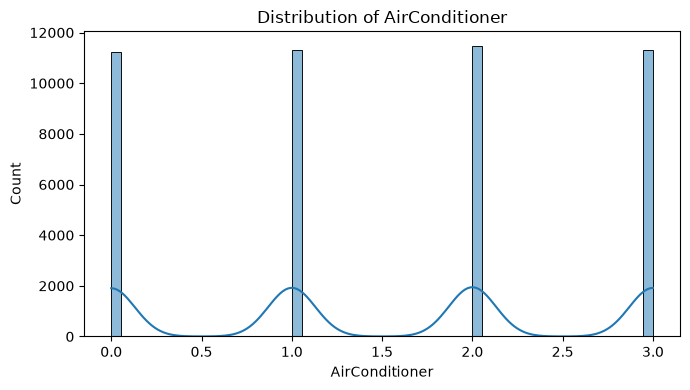

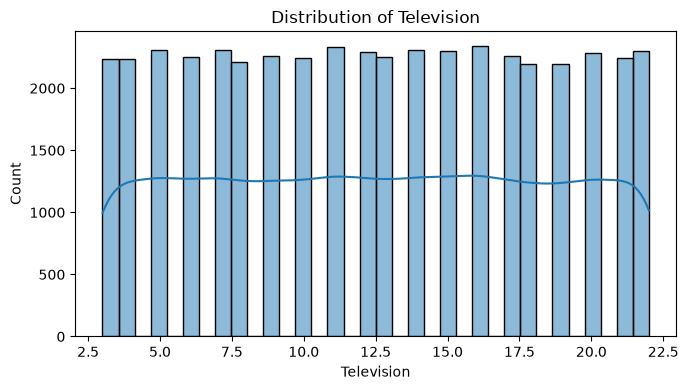

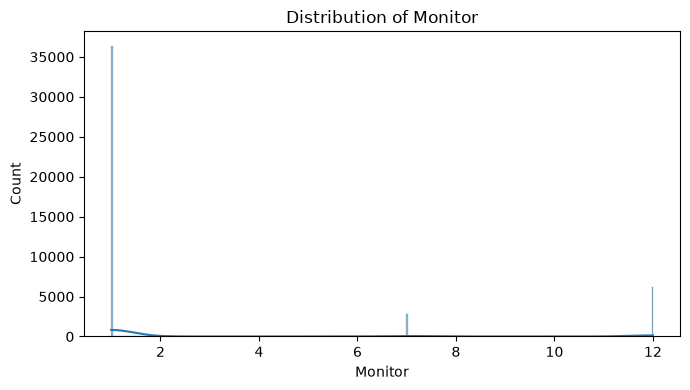

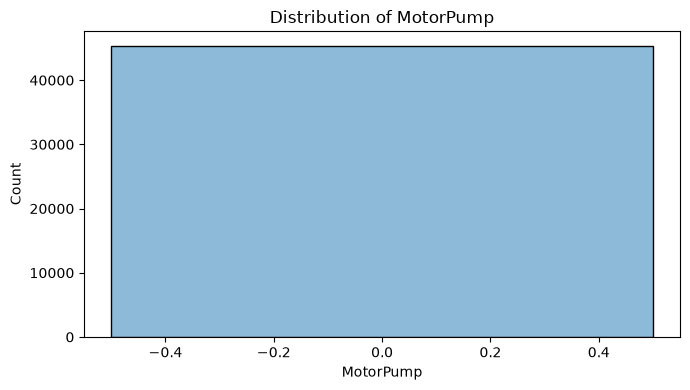

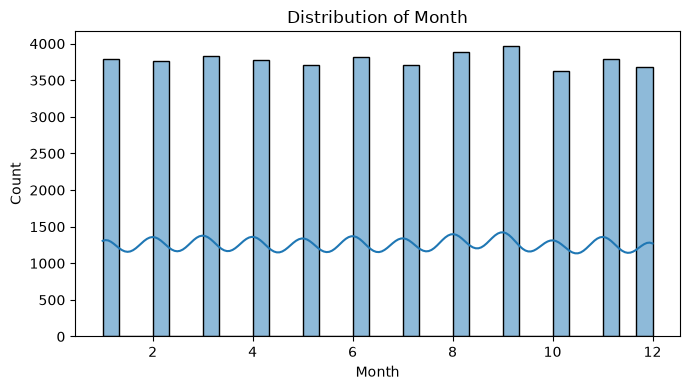

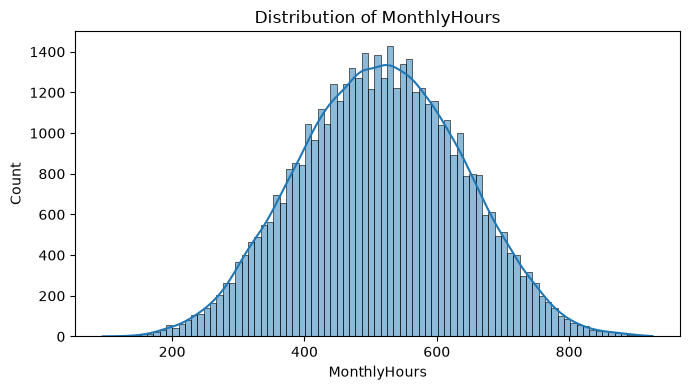

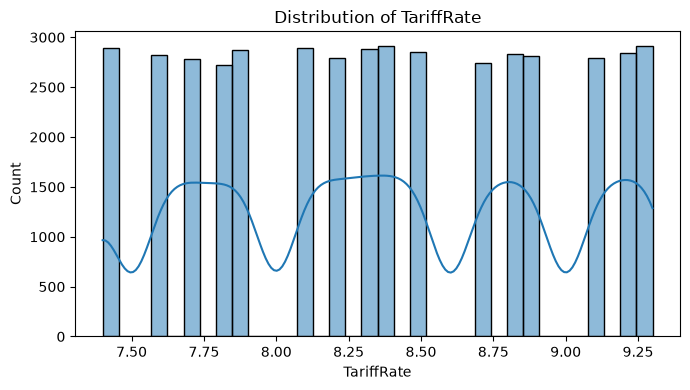

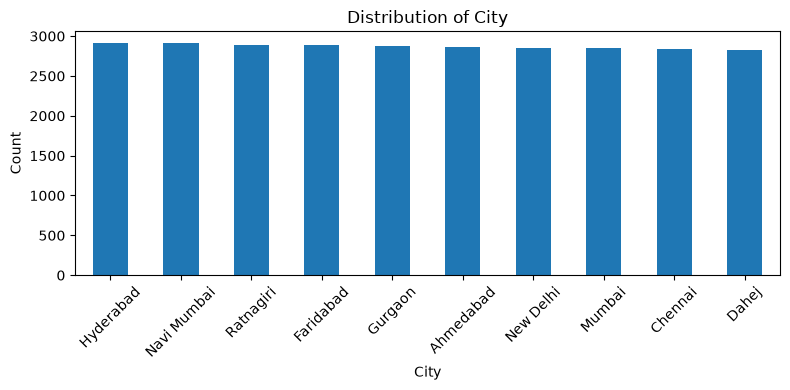

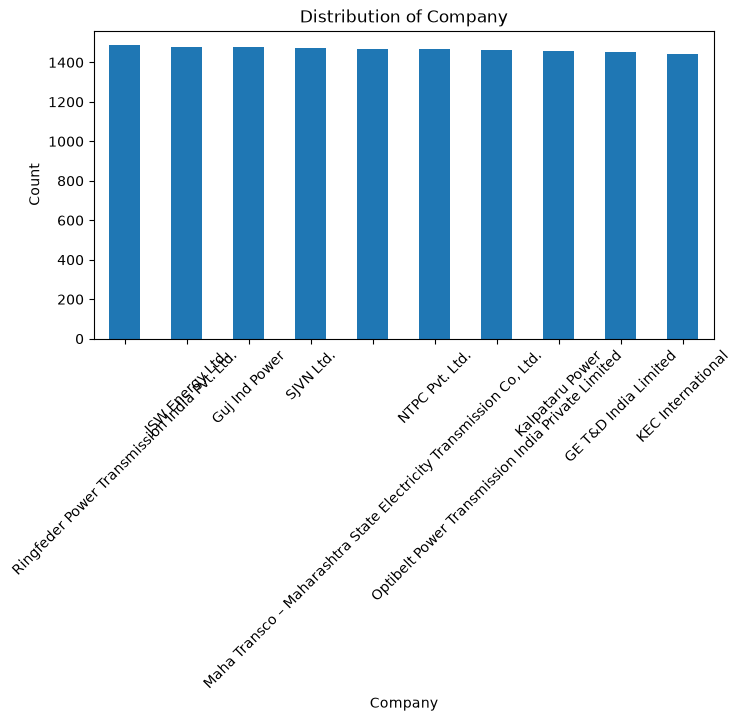


Training Data Shape: (36276, 11)
Testing Data Shape: (9069, 11)

Training: Linear Regression
MAE: 49.267
MSE: 4979.202
RMSE: 70.563
R2 Score: 0.996

Training: Polynomial Regression
MAE: 0.035
MSE: 0.002
RMSE: 0.041
R2 Score: 1.0

Training: Decision Tree
MAE: 6.337
MSE: 142.272
RMSE: 11.928
R2 Score: 1.0

Training: Random Forest
MAE: 1.318
MSE: 28.169
RMSE: 5.307
R2 Score: 1.0

Training: Support Vector Regression
MAE: 49.737
MSE: 5176.77
RMSE: 71.95
R2 Score: 0.995

Training: Gradient Boosting
MAE: 13.671
MSE: 325.867
RMSE: 18.052
R2 Score: 1.0

Training: Linear Regression
MAE: 49.267
MSE: 4979.202
RMSE: 70.563
R2 Score: 0.996

Training: Polynomial Regression
MAE: 0.035
MSE: 0.002
RMSE: 0.041
R2 Score: 1.0

Training: Decision Tree
MAE: 6.337
MSE: 142.272
RMSE: 11.928
R2 Score: 1.0

Training: Random Forest
MAE: 1.318
MSE: 28.169
RMSE: 5.307
R2 Score: 1.0

Training: Support Vector Regression
MAE: 49.737
MSE: 5176.77
RMSE: 71.95
R2 Score: 0.995

Training: Gradient Boosting
MAE: 13.671
MSE

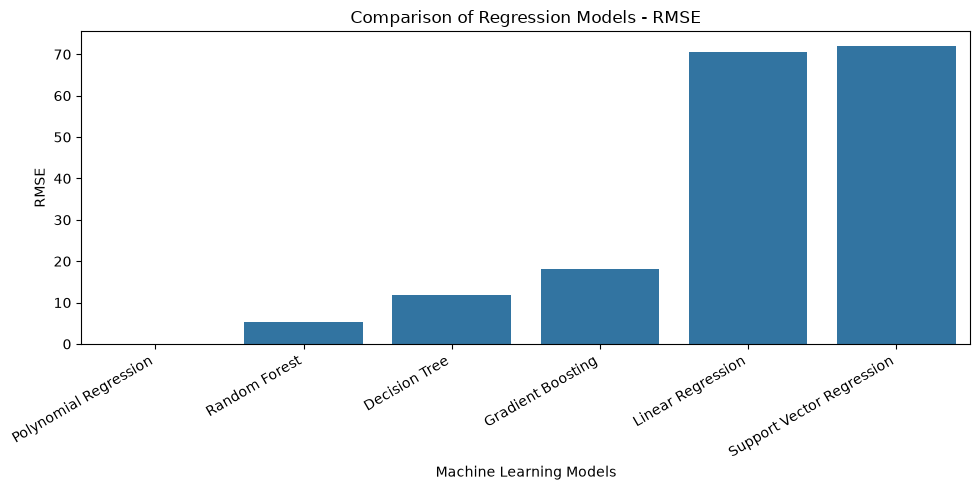

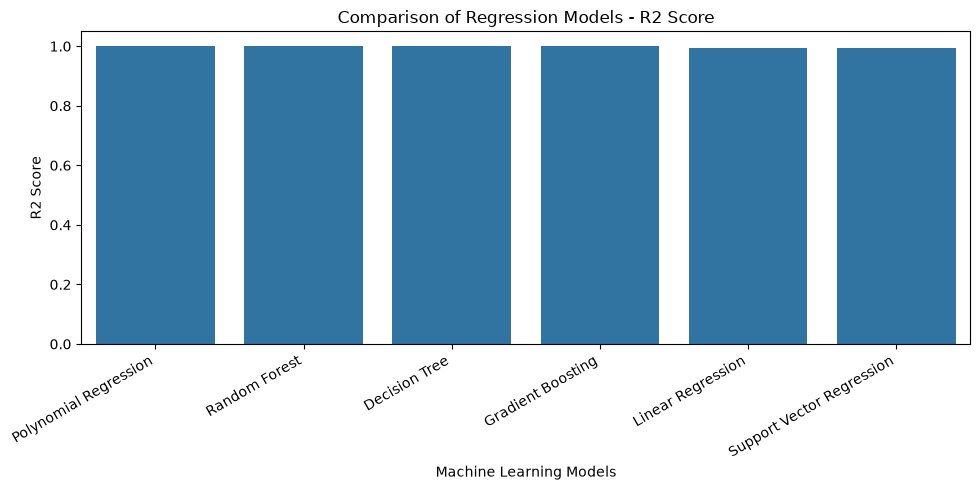


BEST MODEL: Polynomial Regression

Actual vs Predicted Values:
   Actual Electricity Bill  Predicted Electricity Bill
0                   5054.7                 5054.693353
1                   3809.2                 3809.239033
2                   3245.3                 3245.323756
3                   5728.8                 5728.759325
4                   4148.0                 4148.027397
5                   3645.6                 3645.612896
6                   2317.7                 2317.745073
7                   4100.8                 4100.760804
8                   2286.9                 2286.940453
9                   5394.4                 5394.378800


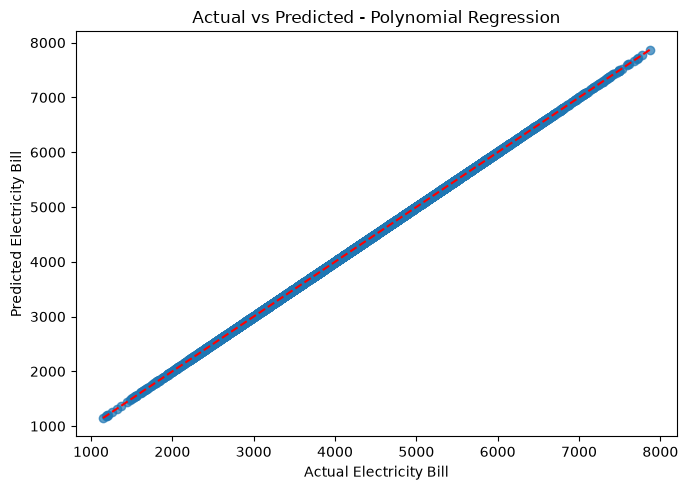

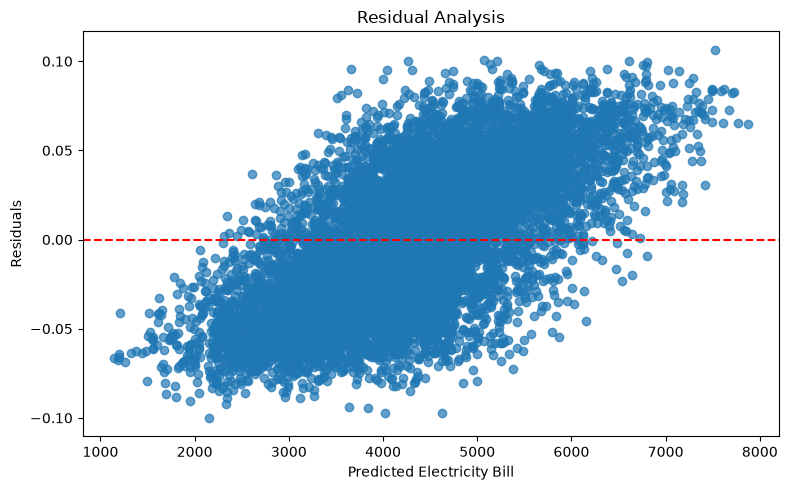


Calculating Feature Importance...

Feature Importance:
       Feature   Importance
  MonthlyHours 2.094273e+06
    TariffRate 1.493477e+05
          City 2.684293e+03
    Television 1.340316e-03
           Fan 5.873567e-04
AirConditioner 5.553988e-04
       Monitor 5.505979e-04
  Refrigerator 3.152498e-04
         Month 1.736693e-05
       Company 1.279925e-05
     MotorPump 0.000000e+00


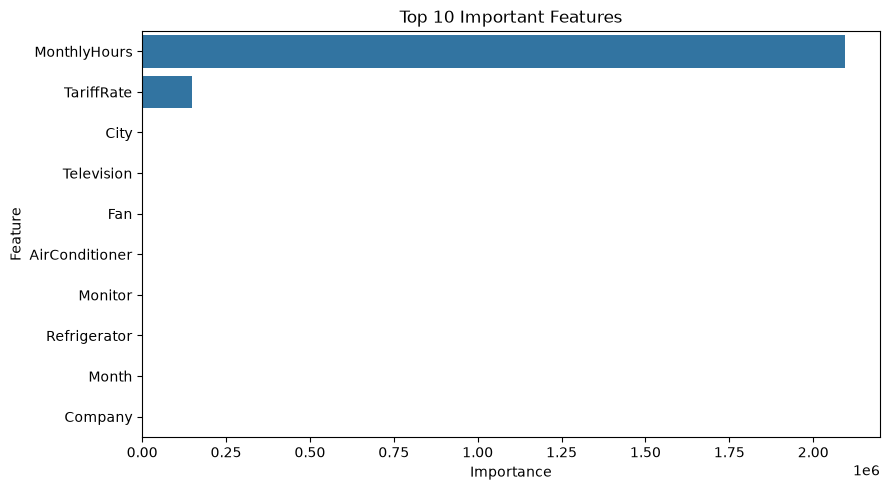


Best model saved successfully!

PROJECT EXECUTION COMPLETED SUCCESSFULLY!

Best Model: Polynomial Regression

All output files are saved inside:
electricity_bill_project_outputs

Generated Files:
1. model_comparison.csv
2. predictions.csv
3. feature_importance.csv
4. best_electricity_bill_model.joblib
5. project_report.txt
6. Model performance graphs

Thank You!


In [1]:
# ============================================================ #
# ELECTRICITY BILL PRICE PREDICTION USING MACHINE LEARNING #
# Comparative Analysis of Regression Models #
# ============================================================ #

# STEP 1: IMPORT LIBRARIES #

import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import LinearSVR

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

import joblib


# ============================================================
# STEP 2: LOAD DATASET
# ============================================================

# Specify the complete path of the CSV dataset
file_path = r"C:\Users\Bhanu\Downloads\electricity_bill_dataset.csv (1)\electricity_bill_dataset.csv"

# Check whether the dataset file exists
if not os.path.exists(file_path):
    raise FileNotFoundError("Dataset file not found. Please check the file path.")

# Load the CSV dataset
df = pd.read_csv(file_path)

# Display successful loading message
print("\nDataset Loaded Successfully!")

# Display first five rows
print("\nFirst 5 Rows:")
print(df.head())

# Display dataset dimensions
print("\nDataset Shape:", df.shape)

# Display all column names
print("\nDataset Columns:")
print(df.columns.tolist())

# STEP 3: DATASET INFORMATION

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Description:")
print(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


# STEP 4: DATA CLEANING

# Remove extra spaces from column names
df.columns = df.columns.astype(str).str.strip()

# Remove duplicate rows
df = df.drop_duplicates()

# Remove completely empty columns
df = df.dropna(axis=1, how="all")

# Try converting object columns to numeric
for column in df.select_dtypes(include="object").columns:
    converted = pd.to_numeric(df[column], errors="coerce")

    if converted.notna().sum() >= 0.90 * df[column].notna().sum():
        df[column] = converted

print("\nDataset after cleaning:")
print(df.head())


# STEP 5: SELECT TARGET COLUMN

# Common names for electricity bill target column
possible_targets = [
    "ElectricityBill",
    "Electricity_Bill",
    "MonthlyBill",
    "Monthly_Bill",
    "BillAmount",
    "Bill_Amount",
    "ElectricityBillAmount",
    "TotalBill",
    "Bill",
    "Amount"
]

target_column = None

for column in df.columns:
    if column.lower().replace(" ", "").replace("_", "") in [
        name.lower().replace(" ", "").replace("_", "")
        for name in possible_targets
    ]:
        target_column = column
        break

if target_column is None:
    print("\nAvailable columns:")
    for column in df.columns:
        print("-", column)

    target_column = input(
        "\nEnter the exact target column name (electricity bill amount): "
    ).strip()

if target_column not in df.columns:
    raise ValueError("Target column not found. Please check the column name.")

print("\nSelected Target Column:", target_column)

# Convert target column to numeric
df[target_column] = pd.to_numeric(df[target_column], errors="coerce")

# Remove rows where target is missing
df = df.dropna(subset=[target_column])

if len(df) < 10:
    raise ValueError("Dataset has too few valid rows for reliable model training.")


# STEP 6: EXPLORATORY DATA ANALYSIS (EDA)

# Target distribution
plt.figure(figsize=(8, 5))
sns.histplot(df[target_column], kde=True)
plt.title("Distribution of Electricity Bill")
plt.xlabel("Electricity Bill Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# Correlation heatmap
numeric_df = df.select_dtypes(include=np.number)

if len(numeric_df.columns) > 1:
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()


# Numerical feature distributions
numeric_features = df.select_dtypes(include=np.number).columns.tolist()

for column in numeric_features:
    if column != target_column:
        plt.figure(figsize=(7, 4))
        sns.histplot(df[column], kde=True)
        plt.title(f"Distribution of {column}")
        plt.tight_layout()
        plt.show()


# Categorical feature distributions
categorical_features = df.select_dtypes(include=["object"]).columns.tolist()

for column in categorical_features:
    plt.figure(figsize=(8, 4))
    df[column].value_counts().head(10).plot(kind="bar")
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


# STEP 7: SEPARATE FEATURES AND TARGET

X = df.drop(columns=[target_column])
y = df[target_column]

# Remove columns that are likely identifiers
id_keywords = ["id", "index", "serial", "customer_id", "household_id"]

columns_to_remove = [
    column for column in X.columns
    if any(keyword in column.lower().replace(" ", "_") for keyword in id_keywords)
]

if columns_to_remove:
    print("\nRemoving identifier columns:", columns_to_remove)
    X = X.drop(columns=columns_to_remove)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

if len(numeric_features) + len(categorical_features) == 0:
    raise ValueError("No usable feature columns found in the dataset.")


# STEP 8: DATA PREPROCESSING

# Numerical data preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical data preprocessing
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)


# STEP 9: TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)



# STEP 10: BUILD MACHINE LEARNING MODELS

models = {
    "Linear Regression": LinearRegression(),

    "Polynomial Regression": Pipeline(steps=[
        ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
        ("regression", Ridge(alpha=1.0))
    ]),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    # Faster alternative to RBF Support Vector Regression
    "Support Vector Regression": LinearSVR(
        C=1.0,
        max_iter=10000,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}


# STEP 11: TRAIN AND EVALUATE MODELS

results = []
trained_models = {}

for model_name, model in models.items():

    print("\nTraining:", model_name, flush=True)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[model_name] = pipeline

    print("MAE:", round(mae, 3))
    print("MSE:", round(mse, 3))
    print("RMSE:", round(rmse, 3))
    print("R2 Score:", round(r2, 3))


# STEP 11: TRAIN AND EVALUATE MODELS

results = []
trained_models = {}

for model_name, model in models.items():

    print("\nTraining:", model_name)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[model_name] = pipeline

    print("MAE:", round(mae, 3))
    print("MSE:", round(mse, 3))
    print("RMSE:", round(rmse, 3))
    print("R2 Score:", round(r2, 3))


# STEP 12: MODEL COMPARISON

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by="RMSE")

print("\n========== MODEL COMPARISON ==========")
print(results_df.to_string(index=False))

os.makedirs("electricity_bill_project_outputs", exist_ok=True)

results_df.to_csv(
    "electricity_bill_project_outputs/model_comparison.csv",
    index=False
)


# STEP 13: VISUALIZE MODEL PERFORMANCE

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("Comparison of Regression Models - RMSE")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("electricity_bill_project_outputs/model_comparison.png")
plt.show()


plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score")
plt.title("Comparison of Regression Models - R2 Score")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("electricity_bill_project_outputs/r2_comparison.png")
plt.show()


# STEP 14: SELECT BEST MODEL

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\n====================================")
print("BEST MODEL:", best_model_name)
print("====================================")

best_predictions = best_model.predict(X_test)


# STEP 15: ACTUAL VS PREDICTED VALUES

comparison = pd.DataFrame({
    "Actual Electricity Bill": y_test.values,
    "Predicted Electricity Bill": best_predictions
})

print("\nActual vs Predicted Values:")
print(comparison.head(10))

comparison.to_csv(
    "electricity_bill_project_outputs/predictions.csv",
    index=False
)


plt.figure(figsize=(7, 5))
plt.scatter(y_test, best_predictions, alpha=0.7)

minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum], "r--")
plt.xlabel("Actual Electricity Bill")
plt.ylabel("Predicted Electricity Bill")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.tight_layout()
plt.savefig("electricity_bill_project_outputs/actual_vs_predicted.png")
plt.show()


# STEP 16: RESIDUAL ANALYSIS

residuals = y_test.values - best_predictions

plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Electricity Bill")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.tight_layout()
plt.savefig("electricity_bill_project_outputs/residual_analysis.png")
plt.show()


# STEP 17: FEATURE IMPORTANCE

print("\nCalculating Feature Importance...")

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_squared_error"
)

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
print(feature_importance.to_string(index=False))

feature_importance.to_csv(
    "electricity_bill_project_outputs/feature_importance.csv",
    index=False
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Important Features")
plt.tight_layout()
plt.savefig("electricity_bill_project_outputs/feature_importance.png")
plt.show()


# STEP 18: SAVE BEST MODEL

joblib.dump(
    best_model,
    "electricity_bill_project_outputs/best_electricity_bill_model.joblib"
)

print("\nBest model saved successfully!")




# STEP 20: FINAL OUTPUT

print("\n========================================")
print("PROJECT EXECUTION COMPLETED SUCCESSFULLY!")
print("========================================")

print("\nBest Model:", best_model_name)

print("\nAll output files are saved inside:")
print("electricity_bill_project_outputs")

print("\nGenerated Files:")
print("1. model_comparison.csv")
print("2. predictions.csv")
print("3. feature_importance.csv")
print("4. best_electricity_bill_model.joblib")
print("5. project_report.txt")
print("6. Model performance graphs")

print("\nThank You!")